Eric Arnold

ML Midterm

Prof. Khoei

In [1]:
import polars as pl
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np
from sklearn.model_selection import train_test_split
from pprint import pprint

from scipy.stats import chi2_contingency
from collections import defaultdict

from sklearn.decomposition import PCA
from sklearn.cluster import HDBSCAN
from sklearn.metrics import adjusted_rand_score
import networkx as nx
import umap
from sklearn.preprocessing import StandardScaler

## Load datasets

When loading, polars did not automatically recognize any of the dtypes, so I had to manually cast them. Some categories in the Assess portion of the dataset are actually floats, but they were very large, so rounding introduced by casting them as integers is small.

In [2]:
cols = ['ID', 'CENTER', 'FY', 'SIC', 'NAICS', 'STATE', 'SALES', 'EMPLOYEES', 'PLANT_AREA', 'PRODUCTS', 'PRODUNITS', 'PRODLEVEL', 'PRODHOURS', 'RECC_COUNT_recc', 'EC_plant_cost', 'EC_plant_usage', 'ED_plant_cost', 'ED_plant_usage', 'EF_plant_cost', 'E2_plant_cost', 'E2_plant_usage', 'E3_plant_cost', 'E3_plant_usage', 'E4_plant_cost', 'E4_plant_usage', 'E5_plant_cost', 'E5_plant_usage', 'E6_plant_cost', 'E6_plant_usage', 'E7_plant_cost', 'E7_plant_usage', 'E8_plant_cost', 'E8_plant_usage', 'E9_plant_cost', 'E9_plant_usage', 'E10_plant_cost', 'E10_plant_usage', 'E11_plant_cost', 'E11_plant_usage', 'E12_plant_cost', 'E12_plant_usage', 'W0_plant_cost', 'W0_plant_usage', 'W1_plant_cost', 'W1_plant_usage', 'W2_plant_cost', 'W2_plant_usage', 'W3_plant_cost', 'W3_plant_usage', 'W4_plant_cost', 'W4_plant_usage', 'W5_plant_cost', 'W5_plant_usage', 'W6_plant_cost', 'W6_plant_usage']
str_cols = ["ID", "CENTER", "SIC", "NAICS", "STATE", "PRODUCTS"] 
int_cols = [c for c in cols if c not in str_cols]
schema = {c: pl.Utf8 for c in str_cols} | {c: pl.Int64 for c in int_cols}

ASSESS = pl.read_excel("ITAC_Database_20261002.xlsx", sheet_name="ASSESS", schema_overrides=schema)

cols = ['SUPERID', 'ID', 'ARC2', 'IMPSTATUS', 'IMPCOST', 'PSOURCCODE', 'PCONSERVED', 'PSOURCONSV', 'PSAVED', 'SSOURCCODE', 'SCONSERVED', 'SSOURCONSV', 'SSAVED', 'TSOURCCODE', 'TCONSERVED', 'TSOURCONSV', 'TSAVED', 'QSOURCCODE', 'QCONSERVED', 'QSOURCONSV', 'QSAVED', 'REBATE', 'INCREMNTAL', 'FY', 'IC_CAPITAL', 'IC_OTHER', 'PAYBACK', 'BPTOOL']
str_cols = ["SUPERID", "ID", "AR_NUMBER", "IMPSTATUS", "BPTOOL", "PSOURCCODE", "SSOURCCODE", "TSOURCCODE", "QSOURCCODE", "REBATE", "INCREMNTAL"]
float_cols = ["ARC2", "PAYBACK"]
int_cols = ["APPCODE", "AR_NUMBER", "FY", "IMPCOST", "PCONSERVED", "PSOURCONSV", "PSAVED", "SCONSERVED", "SSOURCONSV", "SSAVED", "TCONSERVED", "TSOURCONSV", "TSAVED", "QCONSERVED", "QSOURCONSV", "QSAVED", "IC_CAPITAL", "IC_OTHER"]
schema = ({c: pl.Utf8 for c in str_cols} | {c: pl.Float64 for c in float_cols} | {c: pl.Int64 for c in int_cols})


RECC = pl.read_excel("ITAC_Database_20261002.xlsx", sheet_name="RECC", schema_overrides=schema)

# Problem Statement

The Industrial Training and Assessment Centers (ITAC) organization is a DOE program that assesses industrial facilities, chiefly small and medium-sized factories, and makes recommendations about how to save energy and money on production, roughly speaking. The dataset indicates whether or not the recommended changes were implemented, how much it cost, and how much was saved (in terms of resource units, which might be gallons of fuel, kilowatts of electricity, etc.).

The obvious thing to comb through all the variables and see if any are associated with implementation of recommendations, and subsequent savings.

https://catalog.data.gov/dataset/industrial-assessment-centers-database

In [3]:
ASSESS_ids = ASSESS["ID"].unique()
RECC_ids = RECC["ID"].unique()
null_recc_ids = RECC_ids.filter(~RECC_ids.is_in(ASSESS_ids.implode()))
null_assess_ids = ASSESS_ids.filter(~ASSESS_ids.is_in(RECC_ids.implode()))
print(null_recc_ids)
print(null_assess_ids)
RECC = RECC.filter(~pl.col("ID").is_in(null_recc_ids.implode()))
# fig = go.Figure(go.Histogram(RECC[id]))

shape: (3,)
Series: 'ID' [str]
[
	"AM1008"
	"AM1007"
	"CM1056"
]
shape: (0,)
Series: 'ID' [str]
[
]


# EDA

The data can be divided into three sections:

- Assessment data (ASSESS)
    - Categorical
    - Continuous (integer)
- Plant data (ASSESS)
    - Sparse Continuous (integer)
- Outcome data (RECC)
    - Continuous (integer/float)
    - Bernoulli

## Basic Variables

This part of the data covers basic features, such as:

- FY (financial year)                   (integer)
- SIC (industrial code)                 (categorical)
- NAICS (industrial code)               (categorical)
- State                                 (categorical)
- Sales                                 (integer)
- Employees                             (integer)
- Plant Area                            (integer)
- Products                              (string)
- Product unit type                     (categorical)
- Production level                      (integer)
- Production hours annually             (integer)
- Recommendation count                  (integer)

I chose to drop products because these are idiosyncratic strings. We could use a BERT model to categorize them, but these kinds of associations are already handled by the industrial codes.


Here with categorical assessment data, we can see that assessing universities are unevenly distributed, causing the distribution of the number of plants per state to also be unevenly distributed. For splitting our data into train and validate, it makes sense to split by state since whatever regional affects there are probably follow this label.

In [4]:
cat_cols = ["CENTER", "FY", "STATE"]
titles = ["Assessor", "Fiscal Year", "State"]
subs = make_subplots(2, 3, subplot_titles=titles)

for i, col in enumerate(cat_cols):
    x, y = divmod(i, 3)
    subs.add_trace(go.Histogram(x=ASSESS[col].to_list()), row=x+1, col=y+1)

subs.update_xaxes(title_text="State", col=1, row=1)
subs.update_xaxes(title_text="Year", col=2, row=1)
subs.update_xaxes(title_text="State", col=3, row=1)
subs.update_yaxes(title_text="Count", col=1, row=1)
subs.update_yaxes(title_text="Count", col=2, row=1)
subs.update_yaxes(title_text="Count", col=3, row=1)
subs.update_layout(height=384, width=1280)
subs.show()

NAICS codes are 6-digit codes that describe what kind of industry a business is in. The first three digits correspond to the larger industry, while subsequent digits indicate sub-industries. The source for the codes is https://www.census.gov/naics/?48967.

These perform the same role as SIC codes (Standard Industrial Classification) but are a more modern version. However, I found that many entries have null NAICS, whereas there is only 1 for SIC. So we'll have to use both categorizations to cover the whole dataset. SIC codes: https://www.sec.gov/search-filings/standard-industrial-classification-sic-code-list

In [5]:
naics3_names = {
    # agriculture, mining, utilities, construction
    "111": "Crop production", "112": "Animal production & aquaculture",
    "113": "Forestry & logging", "114": "Fishing, hunting & trapping",
    "115": "Agriculture & forestry support",
    "211": "Oil & gas extraction", "212": "Mining (except oil & gas)",
    "213": "Mining support activities", "221": "Utilities",
    "236": "Construction of buildings", "237": "Heavy & civil engineering construction",
    "238": "Specialty trade contractors",
    # manufacturing
    "311": "Food", "312": "Beverage & tobacco", "313": "Textile mills",
    "314": "Textile product mills", "315": "Apparel", "316": "Leather & allied",
    "321": "Wood products", "322": "Paper", "323": "Printing",
    "324": "Petroleum & coal", "325": "Chemicals", "326": "Plastics & rubber",
    "327": "Nonmetallic minerals", "331": "Primary metals",
    "332": "Fabricated metals", "333": "Machinery",
    "334": "Computer & electronic", "335": "Electrical equipment",
    "336": "Transportation equipment", "337": "Furniture", "339": "Miscellaneous",
    # wholesale and retail
    "423": "Wholesale, durable goods", "424": "Wholesale, nondurable goods",
    "425": "Wholesale agents & brokers",
    "441": "Motor vehicle & parts dealers", "444": "Building material & garden retailers",
    "445": "Food & beverage retailers", "449": "Furniture, home & electronics retailers",
    "455": "General merchandise retailers", "456": "Health & personal care retailers",
    "457": "Gasoline stations & fuel dealers", "458": "Clothing, shoe & jewelry retailers",
    "459": "Sporting, hobby, book & misc retailers",
    # transportation and warehousing
    "481": "Air transportation", "482": "Rail transportation", "483": "Water transportation",
    "484": "Truck transportation", "485": "Transit & ground passenger transportation",
    "486": "Pipeline transportation", "487": "Scenic & sightseeing transportation",
    "488": "Transportation support activities", "491": "Postal service",
    "492": "Couriers & messengers", "493": "Warehousing & storage",
    # information, finance, real estate
    "512": "Motion picture & sound recording", "513": "Publishing",
    "516": "Broadcasting & content providers", "517": "Telecommunications",
    "518": "Computing infrastructure & data processing", "519": "Other information services",
    "521": "Monetary authorities", "522": "Credit intermediation",
    "523": "Securities & investments", "524": "Insurance carriers", "525": "Funds & trusts",
    "531": "Real estate", "532": "Rental & leasing", "533": "Lessors of intangible assets",
    # services
    "541": "Professional, scientific & technical services", "551": "Management of companies",
    "561": "Administrative & support services", "562": "Waste management & remediation",
    "611": "Educational services", "621": "Ambulatory health care", "622": "Hospitals",
    "623": "Nursing & residential care", "624": "Social assistance",
    "711": "Performing arts & spectator sports", "712": "Museums & historical sites",
    "713": "Amusement, gambling & recreation", "721": "Accommodation",
    "722": "Food services & drinking places",
    "811": "Repair & maintenance", "812": "Personal & laundry services",
    "813": "Religious, civic & professional organizations", "814": "Private households",
    # public administration
    "921": "General government support", "922": "Justice, public order & safety",
    "923": "Human resource program administration", "924": "Environmental program administration",
    "925": "Housing & urban development administration", "926": "Economic program administration",
    "927": "Space research & technology", "928": "National security & international affairs",
}

sector_names = {
    "11": "Agriculture, Forestry, Fishing and Hunting",
    "21": "Mining, Quarrying, and Oil and Gas Extraction",
    "22": "Utilities", "23": "Construction",
    "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing",
    "42": "Wholesale Trade", "44": "Retail Trade", "45": "Retail Trade",
    "48": "Transportation and Warehousing", "49": "Transportation and Warehousing",
    "51": "Information", "52": "Finance and Insurance",
    "53": "Real Estate and Rental and Leasing",
    "54": "Professional, Scientific, and Technical Services",
    "55": "Management of Companies and Enterprises",
    "56": "Administrative and Support and Waste Management and Remediation Services",
    "61": "Educational Services", "62": "Health Care and Social Assistance",
    "71": "Arts, Entertainment, and Recreation", "72": "Accommodation and Food Services",
    "81": "Other Services (except Public Administration)", "92": "Public Administration",
}

ASSESS = ASSESS.with_columns(NAICS2=pl.col("NAICS").str.slice(0, 2),NAICS3=pl.col("NAICS").str.slice(0, 3),
).with_columns(NAICS2_name=pl.col("NAICS2").replace_strict(sector_names, default=None, return_dtype=pl.Utf8),
NAICS3_name=pl.col("NAICS3").replace_strict(naics3_names, default=None, return_dtype=pl.Utf8),
)

sic2_names = {
    "01": "Agricultural production, crops", "02": "Agricultural production, livestock",
    "07": "Agricultural services", "08": "Forestry", "09": "Fishing, hunting & trapping",
    "10": "Metal mining", "12": "Coal mining", "13": "Oil & gas extraction",
    "14": "Nonmetallic minerals mining", "15": "Building construction",
    "16": "Heavy construction", "17": "Special trade contractors",
    "20": "Food & kindred products", "21": "Tobacco products", "22": "Textile mill products",
    "23": "Apparel", "24": "Lumber & wood products", "25": "Furniture & fixtures",
    "26": "Paper & allied products", "27": "Printing & publishing", "28": "Chemicals & allied products",
    "29": "Petroleum refining", "30": "Rubber & misc plastics", "31": "Leather products",
    "32": "Stone, clay, glass & concrete", "33": "Primary metals", "34": "Fabricated metals",
    "35": "Industrial machinery & equipment", "36": "Electronic & electrical equipment",
    "37": "Transportation equipment", "38": "Instruments & related products",
    "39": "Miscellaneous manufacturing",
    "40": "Railroad transportation", "41": "Local passenger transit", "42": "Trucking & warehousing",
    "43": "Postal service", "44": "Water transportation", "45": "Air transportation",
    "46": "Pipelines", "47": "Transportation services", "48": "Communications",
    "49": "Electric, gas & sanitary services",
    "50": "Wholesale, durable goods", "51": "Wholesale, nondurable goods",
    "52": "Building materials & garden retail", "53": "General merchandise retail",
    "54": "Food stores", "55": "Auto dealers & gas stations", "56": "Apparel retail",
    "57": "Furniture & home furnishings retail", "58": "Eating & drinking places", "59": "Misc retail",
    "60": "Depository institutions", "61": "Nondepository credit", "62": "Security & commodity brokers",
    "63": "Insurance carriers", "64": "Insurance agents", "65": "Real estate", "67": "Holding & investment offices",
    "70": "Hotels & lodging", "72": "Personal services", "73": "Business services",
    "75": "Auto repair & parking", "76": "Misc repair services", "78": "Motion pictures",
    "79": "Amusement & recreation", "80": "Health services", "81": "Legal services",
    "82": "Educational services", "83": "Social services", "84": "Museums & gardens",
    "86": "Membership organizations", "87": "Engineering & management services",
    "88": "Private households", "89": "Misc services",
    "91": "Executive, legislative & general government", "92": "Justice, public order & safety",
    "93": "Public finance & taxation", "94": "Human resource administration",
    "95": "Environmental quality & housing", "96": "Economic programs administration",
    "97": "National security & international affairs", "99": "Nonclassifiable establishments",
}

ASSESS = ASSESS.with_columns(SIC2=pl.col("SIC").str.zfill(4).str.slice(0, 2),SIC3=pl.col("SIC").str.zfill(4).str.slice(0, 3),
).with_columns(SIC2_name=pl.col("SIC2").replace_strict(sic2_names, default=None, return_dtype=pl.Utf8))

sic3_names = {
    # A: agriculture, forestry, fishing
    "010": "Agricultural Production Crops", "011": "Cash Grains", "013": "Field Crops, Except Cash Grains",
    "016": "Vegetables and Melons", "017": "Fruits and Tree Nuts", "018": "Horticultural Specialties",
    "019": "General Farms, Primarily Crop", "020": "Agricultural Production Livestock and Animal Specialties",
    "021": "Livestock, Except Dairy and Poultry", "024": "Dairy Farms", "025": "Poultry and Eggs",
    "027": "Animal Specialties", "029": "General Farms, Primarily Livestock and Animal Specialties",
    "070": "Agricultural Services", "071": "Soil Preparation Services", "072": "Crop Services",
    "074": "Veterinary Services", "075": "Animal Services, Except Veterinary",
    "076": "Farm Labor and Management Services", "078": "Landscape and Horticultural Services",
    "080": "Forestry", "081": "Timber Tracts", "083": "Forest Nurseries and Gathering of Forest Products",
    "085": "Forestry Services", "090": "Fishing, Hunting, and Trapping", "091": "Commercial Fishing",
    "092": "Fish Hatcheries and Preserves", "097": "Hunting and Trapping, and Game Propagation",
    # B: mining
    "100": "Metal Mining", "101": "Iron Ores", "102": "Copper Ores", "103": "Lead and Zinc Ores",
    "104": "Gold and Silver Ores", "106": "Ferroalloy Ores, Except Vanadium", "108": "Metal Mining Services",
    "109": "Miscellaneous Metal Ores", "120": "Coal Mining", "122": "Bituminous Coal and Lignite Mining",
    "123": "Anthracite Mining", "124": "Coal Mining Services", "130": "Oil and Gas Extraction",
    "131": "Crude Petroleum and Natural Gas", "132": "Natural Gas Liquids", "138": "Oil and Gas Field Services",
    "140": "Mining and Quarrying of Nonmetallic Minerals, Except Fuels", "141": "Dimension Stone",
    "142": "Crushed and Broken Stone, Including Riprap", "144": "Sand and Gravel",
    "145": "Clay, Ceramic, and Refractory Minerals", "147": "Chemical and Fertilizer Mineral Mining",
    "148": "Nonmetallic Minerals Services, Except Fuels", "149": "Miscellaneous Nonmetallic Minerals, Except Fuels",
    # C: construction
    "150": "Building Construction General Contractors and Operative Builders",
    "152": "General Building Contractors-Residential", "153": "Operative Builders",
    "154": "General Building Contractors-Nonresidential",
    "160": "Heavy Construction Other Than Building Construction Contractors",
    "161": "Highway and Street Construction, Except Elevated Highways",   # completed (truncated in source)
    "162": "Heavy Construction, Except Highway and Street", "170": "Construction Special Trade Contractors",
    "171": "Plumbing, Heating and Air-Conditioning", "172": "Painting and Paper Hanging",
    "173": "Electrical Work", "174": "Masonry, Stonework, Tile Setting, and Plastering",
    "175": "Carpentry and Floor Work", "176": "Roofing, Siding, and Sheet Metal Work", "177": "Concrete Work",
    "178": "Water Well Drilling", "179": "Miscellaneous Special Trade Contractors",
    # D: manufacturing (20-23)
    "200": "Food and Kindred Products", "201": "Meat Products", "202": "Dairy Products",
    "203": "Canned, Frozen, and Preserved Fruits, Vegetables, and Food Specialties",
    "204": "Grain Mill Products", "205": "Bakery Products", "206": "Sugar and Confectionery Products",
    "207": "Fats and Oils", "208": "Beverages",
    "209": "Miscellaneous Food Preparations and Kindred Products",   # completed
    "210": "Tobacco Products", "211": "Cigarettes", "212": "Cigars",
    "213": "Chewing and Smoking Tobacco and Snuff", "214": "Tobacco Stemming and Redrying",
    "220": "Textile Mill Products", "221": "Broadwoven Fabric Mills, Cotton",
    "222": "Broadwoven Fabric Mills, Manmade Fiber and Silk",
    "223": "Broadwoven Fabric Mills, Wool (Including Dyeing and Finishing)",
    "224": "Narrow Fabric and Other Smallwares Mills: Cotton, Wool, Silk, and Manmade Fiber",
    "225": "Knitting Mills", "226": "Dyeing and Finishing Textiles, Except Wool Fabrics",
    "227": "Carpets and Rugs", "228": "Yarn and Thread Mills", "229": "Miscellaneous Textile Goods",
    "230": "Apparel and Other Finished Products Made From Fabrics and Similar Materials",
    "231": "Men's and Boys' Suits, Coats, and Overcoats",
    "232": "Men's and Boys' Furnishings, Work Clothing, and Allied Garments",
    "233": "Women's, Misses', and Juniors' Outerwear",
    "234": "Women's, Misses', Children's, and Infants' Undergarments", "235": "Hats, Caps, and Millinery",
    "236": "Girls', Children's, and Infants' Outerwear", "237": "Fur Goods",
    "238": "Miscellaneous Apparel and Accessories", "239": "Miscellaneous Fabricated Textile Products",
    # D: manufacturing (24-29)
    "240": "Lumber and Wood Products, Except Furniture", "241": "Logging",
    "242": "Sawmills and Planing Mills, General",
    "243": "Millwork, Veneer, Plywood, and Structural Wood Members",   # completed
    "244": "Wood Containers", "245": "Wood Buildings and Mobile Homes", "249": "Miscellaneous Wood Products",
    "250": "Furniture and Fixtures", "251": "Household Furniture", "252": "Office Furniture",
    "253": "Public Building and Related Furniture",
    "254": "Partitions, Shelving, Lockers, and Office and Store Fixtures",   # completed
    "259": "Miscellaneous Furniture and Fixtures", "260": "Paper and Allied Products", "261": "Pulp Mills",
    "262": "Paper Mills", "263": "Paperboard Mills", "265": "Paperboard Containers and Boxes",
    "267": "Converted Paper and Paperboard Products, Except Containers and Boxes",
    "270": "Printing, Publishing, and Allied Industries",
    "271": "Newspapers: Publishing, or Publishing and Printing",
    "272": "Periodicals: Publishing, or Publishing and Printing", "273": "Books",
    "274": "Miscellaneous Publishing", "275": "Commercial Printing", "276": "Manifold Business Forms",
    "277": "Greeting Cards", "278": "Blankbooks, Looseleaf Binders, and Bookbinding",
    "279": "Service Industries for the Printing Trade", "280": "Chemicals and Allied Products",
    "281": "Industrial Inorganic Chemicals",
    "282": "Plastics Materials and Synthetic Resins, Synthetic Rubber, Cellulosic and Other Manmade Fibers, Except Glass",
    "283": "Drugs",
    "284": "Soap, Detergents, and Cleaning Preparations; Perfumes, Cosmetics, and Other Toilet Preparations",
    "285": "Paints, Varnishes, Lacquers, Enamels, and Allied Products", "286": "Industrial Organic Chemicals",
    "287": "Agricultural Chemicals", "289": "Miscellaneous Chemical Products",
    "290": "Petroleum Refining and Related Industries", "291": "Petroleum Refining",
    "295": "Asphalt Paving and Roofing Materials", "299": "Miscellaneous Products of Petroleum and Coal",
    # D: manufacturing (30-33)
    "300": "Rubber and Miscellaneous Plastics Products", "301": "Tires and Inner Tubes",
    "302": "Rubber and Plastics Footwear",
    "305": "Gaskets, Packing, and Sealing Devices and Rubber and Plastics Hose",   # completed
    "306": "Fabricated Rubber Products, Not Elsewhere Classified", "308": "Miscellaneous Plastics Products",
    "310": "Leather and Leather Products", "311": "Leather Tanning and Finishing",
    "313": "Boot and Shoe Cut Stock and Findings", "314": "Footwear, Except Rubber",
    "315": "Leather Gloves and Mittens", "316": "Luggage", "317": "Handbags and Other Personal Leather Goods",
    "319": "Leather Goods, Not Elsewhere Classified", "320": "Stone, Clay, Glass, and Concrete Products",
    "321": "Flat Glass", "322": "Glass and Glassware, Pressed or Blown", "323": "Glass Products, Made of Purchased Glass",
    "324": "Cement, Hydraulic", "325": "Structural Clay Products", "326": "Pottery and Related Products",
    "327": "Concrete, Gypsum, and Plaster Products", "328": "Cut Stone and Stone Products",
    "329": "Abrasive, Asbestos, and Miscellaneous Nonmetallic Mineral Products",   # completed
    "330": "Primary Metal Industries",
    "331": "Steel Works, Blast Furnaces, and Rolling and Finishing Mills",   # completed
    "332": "Iron and Steel Foundries", "333": "Primary Smelting and Refining of Nonferrous Metals",
    "334": "Secondary Smelting and Refining of Nonferrous Metals",
    "335": "Rolling, Drawing, and Extruding of Nonferrous Metals", "336": "Nonferrous Foundries (Castings)",
    "339": "Miscellaneous Primary Metal Products",
    # D: manufacturing (34-35)
    "340": "Fabricated Metal Products, Except Machinery and Transportation Equipment",
    "341": "Metal Cans and Shipping Containers", "342": "Cutlery, Handtools, and General Hardware",
    "343": "Heating Equipment, Except Electric and Warm Air; and Plumbing Fixtures",
    "344": "Fabricated Structural Metal Products",
    "345": "Screw Machine Products, and Bolts, Nuts, Screws, Rivets, and Washers",
    "346": "Metal Forgings and Stampings", "347": "Coating, Engraving, and Allied Services",
    "348": "Ordnance and Accessories, Except Vehicles and Guided Missiles",
    "349": "Miscellaneous Fabricated Metal Products",
    "350": "Industrial and Commercial Machinery and Computer Equipment", "351": "Engines and Turbines",
    "352": "Farm and Garden Machinery and Equipment",
    "353": "Construction, Mining, and Materials Handling Machinery and Equipment",   # completed
    "354": "Metalworking Machinery and Equipment", "355": "Special Industry Machinery, Except Metalworking",
    "356": "General Industrial Machinery and Equipment", "357": "Computer and Office Equipment",
    "358": "Refrigeration and Service Industry Machinery",
    "359": "Miscellaneous Industrial and Commercial Machinery and Equipment",
    # D: manufacturing (36-39)
    "360": "Electronic and Other Electrical Equipment and Components, Except Computer Equipment",
    "361": "Electric Transmission and Distribution Equipment", "362": "Electrical Industrial Apparatus",
    "363": "Household Appliances", "364": "Electric Lighting and Wiring Equipment",
    "365": "Household Audio and Video Equipment, and Audio Recordings", "366": "Communications Equipment",
    "367": "Electronic Components and Accessories",
    "369": "Miscellaneous Electrical Machinery, Equipment, and Supplies", "370": "Transportation Equipment",
    "371": "Motor Vehicles and Motor Vehicle Equipment", "372": "Aircraft and Parts",
    "373": "Ship and Boat Building and Repairing", "374": "Railroad Equipment",
    "375": "Motorcycles, Bicycles, and Parts", "376": "Guided Missiles and Space Vehicles and Parts",
    "379": "Miscellaneous Transportation Equipment",
    "380": "Measuring, Analyzing, and Controlling Instruments; Photographic, Medical and Optical Goods; Watches and Clocks",
    "381": "Search, Detection, Navigation, Guidance, Aeronautical, and Nautical Systems, Instruments, and Equipment",
    "382": "Laboratory Apparatus and Analytical, Optical, Measuring, and Controlling Instruments",
    "384": "Surgical, Medical, and Dental Instruments and Supplies", "385": "Ophthalmic Goods",
    "386": "Photographic Equipment and Supplies", "387": "Watches, Clocks, Clockwork Operated Devices, and Parts",
    "390": "Miscellaneous Manufacturing Industries", "391": "Jewelry, Silverware, and Plated Ware",
    "393": "Musical Instruments", "394": "Dolls, Toys, Games and Sporting and Athletic Goods",   # completed
    "395": "Pens, Pencils, and Other Artists' Materials",
    "396": "Costume Jewelry, Costume Novelties, Buttons, and Miscellaneous Notions, Except Precious Metal",
    "399": "Miscellaneous Manufacturing Industries",
    # E: transportation, communications, utilities
    "400": "Railroad Transportation", "401": "Railroads",
    "410": "Local and Suburban Transit and Interurban Highway Passenger Transportation",
    "411": "Local and Suburban Passenger Transportation", "412": "Taxicabs",
    "413": "Intercity and Rural Bus Transportation", "414": "Bus Charter Service", "415": "School Buses",
    "417": "Terminal and Service Facilities for Motor Vehicle Passenger Transportation",
    "420": "Motor Freight Transportation and Warehousing", "421": "Trucking and Courier Services, Except Air",
    "422": "Public Warehousing and Storage",
    "423": "Terminal and Joint Terminal Maintenance Facilities for Motor Freight Transportation",   # completed
    "430": "United States Postal Service", "431": "United States Postal Service", "440": "Water Transportation",
    "441": "Deep Sea Foreign Transportation of Freight", "442": "Deep Sea Domestic Transportation of Freight",
    "443": "Freight Transportation on the Great Lakes-St. Lawrence Seaway",
    "444": "Water Transportation of Freight, Not Elsewhere Classified", "448": "Water Transportation of Passengers",
    "449": "Services Incidental to Water Transportation", "450": "Transportation by Air",
    "451": "Air Transportation, Scheduled, and Air Courier", "452": "Air Transportation, Nonscheduled",
    "458": "Airports, Flying Fields, and Airport Terminal Services", "460": "Pipelines, Except Natural Gas",
    "461": "Pipelines, Except Natural Gas", "470": "Transportation Services",
    "472": "Arrangement of Passenger Transportation", "473": "Arrangement of Transportation of Freight and Cargo",
    "474": "Rental of Railroad Cars", "478": "Miscellaneous Services Incidental to Transportation",
    "480": "Communications", "481": "Telephone Communications", "482": "Telegraph and Other Message Communications",
    "483": "Radio and Television Broadcasting Stations", "484": "Cable and Other Pay Television Services",
    "489": "Communications Services, Not Elsewhere Classified", "490": "Electric, Gas, and Sanitary Services",
    "491": "Electric Services", "492": "Gas Production and Distribution",
    "493": "Combination Electric and Gas, and Other Utility Services", "494": "Water Supply",
    "495": "Sanitary Services", "496": "Steam and Air-Conditioning Supply", "497": "Irrigation Systems",
    # F: wholesale trade
    "500": "Wholesale Trade-Durable Goods", "501": "Motor Vehicles and Motor Vehicle Parts and Supplies",
    "502": "Furniture and Home Furnishings", "503": "Lumber and Other Construction Materials",
    "504": "Professional and Commercial Equipment and Supplies", "505": "Metals and Minerals, Except Petroleum",
    "506": "Electrical Goods", "507": "Hardware, and Plumbing and Heating Equipment and Supplies",   # completed
    "508": "Machinery, Equipment, and Supplies", "509": "Miscellaneous Durable Goods",
    "510": "Wholesale Trade-Non-Durable Goods", "511": "Paper and Paper Products",
    "512": "Drugs, Drug Proprietaries, and Druggists' Sundries", "513": "Apparel, Piece Goods, and Notions",
    "514": "Groceries and Related Products", "515": "Farm-Product Raw Materials",
    "516": "Chemicals and Allied Products", "517": "Petroleum and Petroleum Products",
    "518": "Beer, Wine, and Distilled Alcoholic Beverages", "519": "Miscellaneous Non-Durable Goods",
    # G: retail trade
    "520": "Building Materials, Hardware, Garden Supply, and Mobile Home Dealers",
    "521": "Lumber and Other Building Materials Dealers", "523": "Paint, Glass and Wallpaper Stores",
    "525": "Hardware Stores", "526": "Retail Nurseries, Lawn and Garden Supply Stores", "527": "Mobile Home Dealers",
    "530": "General Merchandise Stores", "531": "Department Stores", "533": "Variety Stores",
    "539": "Miscellaneous General Merchandise Stores", "540": "Food Stores", "541": "Grocery Stores",
    "542": "Meat and Fish (Seafood) Markets, Including Freezer Provisioners", "543": "Fruit and Vegetable Markets",
    "544": "Candy, Nut, and Confectionery Stores", "545": "Dairy Products Stores", "546": "Retail Bakeries",
    "549": "Miscellaneous Food Stores", "550": "Automotive Dealers and Gasoline Service Stations",
    "551": "Motor Vehicle Dealers (New and Used)", "552": "Motor Vehicle Dealers (Used Only)",
    "553": "Auto and Home Supply Stores", "554": "Gasoline Service Stations", "555": "Boat Dealers",
    "556": "Recreational Vehicle Dealers", "557": "Motorcycle Dealers",
    "559": "Automotive Dealers, Not Elsewhere Classified", "560": "Apparel and Accessory Stores",
    "561": "Men's and Boys' Clothing and Accessory Stores", "562": "Women's Clothing Stores",
    "563": "Women's Accessory and Specialty Stores", "564": "Children's and Infants' Wear Stores",
    "565": "Family Clothing Stores", "566": "Shoe Stores", "569": "Miscellaneous Apparel and Accessory Stores",
    "570": "Home Furniture, Furnishings, and Equipment Stores", "571": "Home Furniture and Furnishings Stores",
    "572": "Household Appliance Stores", "573": "Radio, Television, Consumer Electronics, and Music Stores",
    "580": "Eating and Drinking Places", "581": "Eating and Drinking Places", "590": "Miscellaneous Retail",
    "591": "Drug Stores and Proprietary Stores", "592": "Liquor Stores", "593": "Used Merchandise Stores",
    "594": "Miscellaneous Shopping Goods Stores", "596": "Nonstore Retailers", "598": "Fuel Dealers",
    "599": "Retail Stores, Not Elsewhere Classified",
    # H: finance, insurance, real estate
    "600": "Depository Institutions", "601": "Central Reserve Depository Institutions", "602": "Commercial Banks",
    "603": "Savings Institutions", "606": "Credit Unions",
    "608": "Foreign Banking and Branches and Agencies of Foreign Banks",
    "609": "Functions Related to Depository Banking", "610": "Non-Depository Credit Institutions",
    "611": "Federal and Federally-Sponsored Credit Agencies", "614": "Personal Credit Institutions",
    "615": "Business Credit Institutions", "616": "Mortgage Bankers and Brokers",
    "620": "Security and Commodity Brokers, Dealers, Exchanges, and Services",
    "621": "Security Brokers, Dealers, and Flotation Companies", "622": "Commodity Contracts Brokers and Dealers",
    "623": "Security and Commodity Exchanges", "628": "Services Allied with the Exchange of Securities",
    "630": "Insurance Carriers", "631": "Life Insurance",
    "632": "Accident and Health Insurance and Medical Service Plans",   # completed
    "633": "Fire, Marine, and Casualty Insurance", "635": "Surety Insurance", "636": "Title Insurance",
    "637": "Pension, Health, and Welfare Funds", "639": "Insurance Carriers, Not Elsewhere Classified",
    "640": "Insurance Agents, Brokers, and Service", "641": "Insurance Agents, Brokers, and Service",
    "650": "Real Estate", "651": "Real Estate Operators (Except Developers) and Lessors",
    "653": "Real Estate Agents and Managers", "654": "Title Abstract Offices",
    "655": "Land Subdividers and Developers", "670": "Holding and Other Investment Offices",
    "671": "Holding Offices", "672": "Investment Offices", "673": "Trusts", "679": "Miscellaneous Investing",
    # I: services
    "700": "Hotels, Rooming Houses, Camps, and Other Lodging Places", "701": "Hotels and Motels",
    "702": "Rooming and Boarding Houses", "703": "Camps and Recreational Vehicle Parks",
    "704": "Organization Hotels and Lodging Houses, on Membership Basis", "720": "Personal Services",
    "721": "Laundry, Cleaning, and Garment Services", "722": "Photographic Studios, Portrait",
    "723": "Beauty Shops", "724": "Barber Shops", "725": "Shoe Repair Shops and Shoeshine Parlors",
    "726": "Funeral Service and Crematories", "729": "Miscellaneous Personal Services", "730": "Business Services",
    "731": "Advertising",
    "732": "Consumer Credit Reporting Agencies, Mercantile Reporting Agencies, and Adjustment and Collection Agencies",   # completed
    "733": "Mailing, Reproduction, Commercial Art and Photography, and Stenographic Services",
    "734": "Services to Dwellings and Other Buildings", "735": "Miscellaneous Equipment Rental and Leasing",
    "736": "Personnel Supply Services", "737": "Computer Programming, Data Processing, and Other Computer Related Services",
    "738": "Miscellaneous Business Services", "750": "Automotive Repair, Services, and Parking",
    "751": "Automotive Rental and Leasing, Without Drivers", "752": "Automobile Parking",
    "753": "Automotive Repair Shops", "754": "Automotive Services, Except Repair",
    "760": "Miscellaneous Repair Services", "762": "Electrical Repair Shops", "763": "Watch, Clock, and Jewelry Repair",
    "764": "Reupholstery and Furniture Repair", "769": "Miscellaneous Repair Shops and Related Services",
    "780": "Motion Pictures", "781": "Motion Picture Production and Allied Services",
    "782": "Motion Picture Distribution and Allied Services", "783": "Motion Picture Theaters",
    "784": "Video Tape Rental", "790": "Amusement and Recreation Services", "791": "Dance Studios, Schools, and Halls",
    "792": "Theatrical Producers (Except Motion Picture), Bands, Orchestras, and Entertainers",   # completed
    "793": "Bowling Centers", "794": "Commercial Sports", "799": "Miscellaneous Amusement and Recreation",
    "800": "Health Services", "801": "Offices and Clinics of Doctors of Medicine",
    "802": "Offices and Clinics of Dentists", "803": "Offices and Clinics of Doctors of Osteopathy",
    "804": "Offices and Clinics of Other Health Practitioners", "805": "Nursing and Personal Care Facilities",
    "806": "Hospitals", "807": "Medical and Dental Laboratories", "808": "Home Health Care Services",
    "809": "Miscellaneous Health and Allied Services, Not Elsewhere Classified", "810": "Legal Services",
    "811": "Legal Services", "820": "Educational Services", "821": "Elementary and Secondary Schools",
    "822": "Colleges, Universities, Professional Schools, and Junior Colleges", "823": "Libraries",
    "824": "Vocational Schools", "829": "Schools and Educational Services, Not Elsewhere Classified",   # completed
    "830": "Social Services", "832": "Individual and Family Social Services",
    "833": "Job Training and Vocational Rehabilitation Services", "835": "Child Day Care Services",
    "836": "Residential Care", "839": "Social Services, Not Elsewhere Classified",
    "840": "Museums, Art Galleries, and Botanical and Zoological Gardens", "841": "Museums and Art Galleries",
    "842": "Arboreta and Botanical or Zoological Gardens", "860": "Membership Organizations",
    "861": "Business Associations", "862": "Professional Membership Organizations",
    "863": "Labor Unions and Similar Labor Organizations", "864": "Civic, Social, and Fraternal Associations",
    "865": "Political Organizations", "866": "Religious Organizations",
    "869": "Membership Organizations, Not Elsewhere Classified",
    "870": "Engineering, Accounting, Research, Management, and Related Services",
    "871": "Engineering, Architectural, and Surveying Services", "872": "Accounting, Auditing, and Bookkeeping Services",
    "873": "Research, Development, and Testing Services", "874": "Management and Public Relations Services",
    "880": "Private Households", "881": "Private Households",
    # government (OES designation)
    "900": "Federal, State, and Local Government (OES designation)", "901": "Federal Government (OES designation)",
    "902": "State Government (OES designation)", "903": "Local Government (OES designation)",
}

ASSESS = ASSESS.with_columns(SIC3_name=pl.col("SIC3").replace_strict(sic3_names, default=None, return_dtype=pl.Utf8),
).with_columns(SIC3_label=pl.coalesce("SIC3_name", "SIC2_name"),)

print("SIC nulls:", ASSESS["SIC"].null_count(), "NAICS nulls:", ASSESS["NAICS"].null_count())

SIC nulls: 1 NAICS nulls: 10970


Per the plot below, we can see that the dataset is biased towards manufacturing in general, (instead of services), and those with NAICS codes describe a subset of manufacturing-related businesses.

In [6]:
sic = (ASSESS.drop_nulls("SIC2").group_by("SIC2", "SIC2_name").len().sort("len", descending=True).with_columns(label=pl.col("SIC2") + " " + pl.col("SIC2_name").fill_null("(unmapped)")))
sec = (ASSESS.drop_nulls("NAICS2").group_by("NAICS2", "NAICS2_name").len().sort("len", descending=True).with_columns(label=pl.col("NAICS2") + " " + pl.col("NAICS2_name").fill_null("(unmapped)")))
sub = (ASSESS.drop_nulls("NAICS3").group_by("NAICS3", "NAICS3_name").len().sort("len", descending=True).with_columns(label=pl.col("NAICS3") + " " + pl.col("NAICS3_name").fill_null("(unmapped)")))

subs = make_subplots(1, 3, subplot_titles=["SIC Major Group (2-digit)", "NAICS Sector (2-digit)", "NAICS Subsector (3-digit)"], horizontal_spacing=0.2)

subs.add_trace(go.Bar(x=sic["len"].to_list(), y=sic["label"].to_list(), orientation="h"), 1, 1)
subs.add_trace(go.Bar(x=sec["len"].to_list(), y=sec["label"].to_list(), orientation="h"), 1, 2)
subs.add_trace(go.Bar(x=sub["len"].to_list(), y=sub["label"].to_list(), orientation="h"), 1, 3)

subs.update_yaxes(type="category", autorange="reversed")   # most common at top
subs.update_xaxes(title_text="Assessments")
subs.update_layout(height=1024, width=1280, showlegend=False, title_text="Assessments by SIC and NAICS Classification")
subs.show()

Per the sankey plot below, we can see that SIC codes are mostly associated with NAICS manufacturing prefixes, and that prefixes add little information over the suffixes since they are broadly associated with many SIC codes. Due to the ubiquitous nature of SIC codes, we can drop NAICS prefixes and fill suffixes with "Other" and rely on SIC codes to distinguish these industries.

In [7]:
def top(col, name_col, n=20):
    return (ASSESS.drop_nulls(col).group_by(col, name_col).len().sort("len", descending=True).head(n))

t_sic, t_n2, t_s3, t_n3 = (
    top("SIC2", "SIC2_name"), top("NAICS2", "NAICS2_name"),
    top("SIC3", "SIC3_label"), top("NAICS3", "NAICS3_name"),
)

flows = (
    ASSESS.filter(
        pl.col("SIC2").is_in(t_sic["SIC2"].implode())
        & pl.col("NAICS2").is_in(t_n2["NAICS2"].implode())
        & pl.col("SIC3").is_in(t_s3["SIC3"].implode())
        & pl.col("NAICS3").is_in(t_n3["NAICS3"].implode())
    )
    .group_by("SIC2", "NAICS2", "SIC3", "NAICS3").len()
)
print(f"{flows['len'].sum()} of {ASSESS.height} assessments shown")

# layers in left-to-right order
layers = [
    ("SIC", t_sic, "SIC2", "SIC2_name"),
    ("S3", t_s3, "SIC3", "SIC3_label"),
    ("N2", t_n2, "NAICS2", "NAICS2_name"),
    ("N3", t_n3, "NAICS3", "NAICS3_name"),
]
# node list: one node per (layer, code)
labels, idx = [], {}
for tag, df, col, name_col in layers:
    for code, name in df.select(col, name_col).iter_rows():
        idx[(tag, code)] = len(labels)
        labels.append(f"{code} {name or '(unmapped)'}")

# links between each pair of adjacent layers
src, tgt, val = [], [], []
for (a_tag, _, a_col, _), (b_tag, _, b_col, _) in zip(layers, layers[1:]):
    for a, b, w in flows.group_by(a_col, b_col).agg(pl.col("len").sum()).iter_rows():
        src.append(idx[(a_tag, a)]); tgt.append(idx[(b_tag, b)]); val.append(w)

fig = go.Figure(go.Sankey(
    node=dict(label=labels, pad=12, thickness=14),
    link=dict(source=src, target=tgt, value=val, color="rgba(120,120,120,0.3)"),
))
fig.update_layout(height=1080, width=1600, title_text="SIC major group, SIC industry group, NAICS sector, NAICS subsector (top 20 each)")
fig.show()

5388 of 23007 assessments shown


Drop original categories and NAICS2, fill nulls in NAICS subcategories with Other, drop the 1 null SIC2.

In [8]:
ASSESS = ASSESS.drop(["SIC", "NAICS", "NAICS2"])
ASSESS = ASSESS.with_columns(pl.col("NAICS3").fill_null("Other")).drop_nulls("SIC2")

Here, I examine the numbers concerning implementations, which is our target variable in this dataset, and assessments. As we can see, these are roughly log-normal, but differentiated across states, adding to the notion that we should balance across state, since this is a significant source of variance.

In [9]:
assessments_per = RECC["ID"].value_counts()["count"].to_list()
implementations_per = RECC.filter(pl.col("IMPSTATUS") == "I")["ID"].value_counts()["count"].to_list()
negs_per = RECC.filter(pl.col("IMPSTATUS") == "N")["ID"].value_counts()["count"].to_list()
state_df = RECC.select("ID", "IMPSTATUS").join(ASSESS.select("ID", "STATE"), on="ID", how="left")
state_df = state_df.group_by("ID", "IMPSTATUS", "STATE").agg(pl.len()).sort("len")
state_assess = state_df.group_by("STATE").agg(pl.col("len").sum()).sort("len")
state_means = state_df.group_by("STATE").agg(pl.col("len").filter(pl.col("IMPSTATUS") == "I").sum() / pl.col("len").sum()).sort(by="len", descending=True)
subs = make_subplots(3, 2, subplot_titles=["Assessments per plant", "Implementations per plant", "Negatives per plant", "Assessments per state", "Mean Implementations/Assessments per plant per state"])

subs.add_trace(go.Histogram(x=assessments_per), 1, 1)
subs.add_trace(go.Histogram(x=implementations_per), 1, 2)
subs.add_trace(go.Histogram(x=negs_per), 2, 1)
subs.add_trace(go.Bar(x=state_assess["STATE"], y=state_assess["len"]), 2, 2)
subs.add_trace(go.Bar(x=state_means["STATE"], y=state_means["len"]), 3, 1)

subs.update_xaxes(title_text="Assessments", row=1, col=1)
subs.update_yaxes(title_text="Plants", row=1, col=1)
subs.update_xaxes(title_text="Implementations", row=1, col=2)
subs.update_yaxes(title_text="Plants", row=1, col=2)
subs.update_xaxes(title_text="Negatives", row=2, col=1)
subs.update_yaxes(title_text="Plants", row=2, col=1)
subs.update_xaxes(title_text="State", row=2, col=2)
subs.update_yaxes(title_text="Assessments", row=2, col=2)
subs.update_xaxes(title_text="State", row=3, col=1)
subs.update_yaxes(title_text="Mean Value", row=3, col=1)
subs.update_layout(height=768, width=1024)

subs.show()

The distribution of implementations per plant is slightly right-shifted compared to negatives per plant, indicating that recommendations are implemented more often than not. There is a huge amount of variability in terms of the ratio of successful implementations to total implementations per state, and in the number of assessments per state. For splitting the dataset into train/val, we probably want to balance our subset by state.

My strategy here is to select the ids and then apply them to the dataframes before I use them, instead of selecting rows.

In [10]:
ids = ASSESS.select("ID", "STATE").unique(subset="ID", keep="first", maintain_order=True)
train_ids, val_ids = train_test_split(ids, test_size=0.2, random_state=0, stratify=ids["STATE"])

### Production Unit (produnit) analysis

IAC defines the unit type for measuring the quantity of a product produced using the following codes:

- 0: N/A
- 1: Pieces
- 2: Pounds
- 3: Tons
- 4: BBL (beer barrel?)
- 5: Thousands of Gallons
- 6: Thousands of Feet or Square Feet
- 7: Bushels

I wanted to verify that there was no significant difference between produnit proportions between train and val as a proxy for "the kind of thing produced." This is because my split did not take into account any information about what kinds of products were produced. Since states might vary greatly in terms of industry type, I wanted to test for this. There were no significant differences subdividing by state or overall.

In [11]:
ASSESS_train = ASSESS.filter(pl.col("ID").is_in(train_ids["ID"].implode()))
ASSESS_val   = ASSESS.filter(pl.col("ID").is_in(val_ids["ID"].implode()))

In [12]:
def chi2_test(col, train, val):
    print(f"\nTESTING {col}")
    cat = pl.concat([train.select(col).with_columns(split=pl.lit("train")),
                     val.select(col).with_columns(split=pl.lit("val"))]).drop_nulls(col)

    tbl = (cat.group_by("split", col).len().pivot(on=col, index="split", values="len").fill_null(0).sort("split"))

    chi2, p, dof, expected = chi2_contingency(tbl.drop("split").to_numpy())
    print("test_stat:", chi2, "p:", p, "dof:", dof)

In [13]:
pu_train = ASSESS.select("ID", "PRODUNITS", "STATE").filter(pl.col("ID").is_in(train_ids["ID"].implode()))
pu_train = pu_train.with_columns(pl.col("PRODUNITS").fill_null(0))
pu_state_train = pu_train.group_by("STATE", "PRODUNITS").agg(pl.len()).sort("STATE", "PRODUNITS")

pu_val = ASSESS.select("ID", "PRODUNITS", "STATE").filter(pl.col("ID").is_in(val_ids["ID"].implode()))
pu_val = pu_val.with_columns(pl.col("PRODUNITS").fill_null(0))
pu_state_val = pu_val.group_by("STATE", "PRODUNITS").agg(pl.len()).sort("STATE", "PRODUNITS")

pu_train = pu_train.with_columns((pl.col("STATE").cast(pl.String) + "_" + pl.col("PRODUNITS").cast(pl.String)).alias("sp"))
pu_val = pu_val.with_columns((pl.col("STATE").cast(pl.String) + "_" + pl.col("PRODUNITS").cast(pl.String)).alias("sp"))

print("Testing STATE x PRODUNITS x Split")
chi2_test("sp", pu_train, pu_val)

chi2_test("PRODUNITS", ASSESS_train, ASSESS_val)

Testing STATE x PRODUNITS x Split

TESTING sp
test_stat: 291.8972229755306 p: 0.96674332956354 dof: 338

TESTING PRODUNITS
test_stat: 1.4200380698275203 p: 0.964628138801543 dof: 6


We can also perform the same test with SIC2 codes. There was no sigificant difference.

In [14]:
pu_train = ASSESS.select("ID", "SIC2", "STATE").filter(pl.col("ID").is_in(train_ids["ID"].implode()))
pu_train = pu_train.with_columns(pl.col("SIC2").fill_null(0))
pu_state_train = pu_train.group_by("STATE", "SIC2").agg(pl.len()).sort("STATE", "SIC2")

pu_val = ASSESS.select("ID", "SIC2", "STATE").filter(pl.col("ID").is_in(val_ids["ID"].implode()))
pu_val = pu_val.with_columns(pl.col("SIC2").fill_null(0))
pu_state_val = pu_val.group_by("STATE", "SIC2").agg(pl.len()).sort("STATE", "SIC2")

pu_train = pu_train.with_columns((pl.col("STATE").cast(pl.String) + "_" + pl.col("SIC2").cast(pl.String)).alias("sp"))
pu_val = pu_val.with_columns((pl.col("STATE").cast(pl.String) + "_" + pl.col("SIC2").cast(pl.String)).alias("sp"))

print("Testing STATE x SIC2 x Split")
chi2_test("sp", pu_train, pu_val)

chi2_test("SIC2", ASSESS_train, ASSESS_val)

Testing STATE x SIC2 x Split

TESTING sp
test_stat: 1258.308652851763 p: 0.28100690049371774 dof: 1230

TESTING SIC2
test_stat: 66.54940899745687 p: 0.5270971281961445 dof: 68


Now that the dataset is split, we can do more EDA on train only.

Here we can examine the relationships between the assessment variables. Since these are upstream from the recommendation, we can treat them as indepdent variables. I'm analyzing these separately from the resource utilization variables since they're relatively dense.

Log transforming the distributions for sales, employees, plant area, prod level, and recc count normalizes these distributions.

Nulls in employees, sales, and prod level seem like good candidates for interpolation within their respective categories (state, produnit). About 1/4 of the data lacks a plant area measurement, and I'd expect that this is associated with agriculture or some industry where this is hard to quanitfy.

For prod hours (annual), a large number of entries have 8600-8700 hours, which across 365 days reflects 24 hours a day of production. I think that anything more than 24/hours a day doesn't make sense, so we can cap these at the maximum possible value. For interpolation, we can probably take the mean of its associate category, depending on how prodhours is assocaited with other variables.

In [15]:
a_cols = ['SALES', 'EMPLOYEES', 'PLANT_AREA', 'PRODLEVEL', 'PRODHOURS', 'RECC_COUNT_recc']
nulls = {cat: ASSESS_train[cat].is_null().sum() + (ASSESS_train[cat] == 0).sum() for cat in a_cols}
pprint(nulls)

sales_trf = ASSESS_train["SALES"].log().to_numpy()
empl_trf = ASSESS_train["EMPLOYEES"].log().to_numpy()
area_trf = ASSESS_train["PLANT_AREA"].log().to_numpy()
lvl_trf = ASSESS_train["PRODLEVEL"].log().to_numpy()
hrs_trf = (ASSESS_train.with_columns(pl.col("PRODHOURS").clip(upper_bound=8760))["PRODHOURS"] / 365).to_numpy()
recc_trf = ASSESS_train["RECC_COUNT_recc"].log().to_numpy()

subs = make_subplots(2, 3, subplot_titles=[f"Distribution of {cat}" for cat in a_cols])
subs.add_trace(go.Histogram(x=sales_trf), 1, 1)
subs.add_trace(go.Histogram(x=empl_trf), 1, 2)
subs.add_trace(go.Histogram(x=area_trf), 1, 3)
subs.add_trace(go.Histogram(x=lvl_trf), 2, 1)
subs.add_trace(go.Histogram(x=hrs_trf), 2, 2)
subs.add_trace(go.Histogram(x=recc_trf), 2, 3)

subs.update_xaxes(title_text="Sales $$ (log scale)", row=1, col=1)
subs.update_yaxes(title_text="Plants", row=1, col=1)
subs.update_xaxes(title_text="Employees (log scale)", row=1, col=2)
subs.update_yaxes(title_text="Plants", row=1, col=2)
subs.update_xaxes(title_text="Plant Area  (log scale)", row=1, col=3)
subs.update_yaxes(title_text="Plants", row=1, col=3)
subs.update_xaxes(title_text="Production Level (log scale)", row=2, col=1)
subs.update_yaxes(title_text="Plants", row=2, col=1)
subs.update_xaxes(title_text="Production Hours / Day", row=2, col=2)
subs.update_yaxes(title_text="Plants", row=2, col=2)
subs.update_xaxes(title_text="Recommendation Count (log scale)", row=2, col=3)
subs.update_yaxes(title_text="Plants", row=2, col=3)

subs.update_layout(height=768, width=1024, showlegend=False)

subs.show()

{'EMPLOYEES': 13,
 'PLANT_AREA': 3262,
 'PRODHOURS': 66,
 'PRODLEVEL': 1008,
 'RECC_COUNT_recc': 0,
 'SALES': 103}


### Correlation Matrix

I chose to use Pearson here because the transformations were mostly successful at normalizing the data, and it is more powerful than Spearman. A large enough amount of the data is non-null for inference on these variables to be robust.

Correlations between the variables are unexpectedly low, which throws a wrench into the interpolation method. Interestingly there is no correlation with year (FY) and sales, which I expected to be related due to inflation, and the fact that the economy is continuously "growing."

In [16]:
corr = pl.DataFrame({"SALES": sales_trf, "EMPLOYEES": empl_trf, "PLANT_AREA": area_trf, "PRODLEVEL": lvl_trf, "PRODHOURS": hrs_trf, "RECC_COUNT_recc": recc_trf, "FY": ASSESS_train["FY"]
}).with_columns(pl.when(pl.all().is_finite()).then(pl.all()).otherwise(None))
print("shape before dropping nulls", corr.shape)
corr_full = corr.drop_nulls()
print("after", corr_full.shape)

corells = corr_full.corr()
fig = go.Figure(go.Heatmap(z = corells.to_numpy(), x = corells.columns, y = corells.columns, zmin=-1, zmax=1, text=np.round(corells.to_numpy(), 2), texttemplate="%{text}"))
fig.update_layout(height=768, width=768, title_text="Correlation Matrix Dense Assessment Variables")
fig.show()

shape before dropping nulls (18404, 7)
after (14511, 7)


## Sparse Assessment Data

This category of the dataset deals with resource consumption, such as electrical consumption, steam consumption, natural gas consumption, etc., and waste generation. I approached this set of variables separately because most plants contain only a subset of resources utilized and wastes generated. My plan for these variables is to treat zeros as zeros and use either PCA or UMAP to do dimensionality reduction. I expect UMAP to handle sparsity better since it uses euclidean distance and does not consider directions of variance individually (as a linear combination), but I'll use PCA to see about how many dimensions reside in the data.

### Correlation Matrices

Correlation analysis shows that only strong relationships exist between usages and costs. Electricity and natural gas are somewhat correlated. Costs between resources are somewhat correlated I would suspect because regional variation. Electrical demand usage and electrical usage are not correlated, which is interesting. Electrical demand deals with power supplied in a timely fashion, e.g. for a particular machine, whereas electrical usage characterizes steady-state power consumption. This can be thought of as the difference between streamed tokens versus batched ones -- the former costs more because it's served in real time.

Waste has hardly any correlations at all. The absence of linear relationships across the data mean that PCA will not perform well.

In [17]:
energies = ['EC_plant_cost', 'EC_plant_usage', 'ED_plant_cost', 'ED_plant_usage', 'EF_plant_cost', 'E2_plant_cost', 'E2_plant_usage', 'E3_plant_cost', 'E3_plant_usage', 'E4_plant_cost', 'E4_plant_usage', 'E5_plant_cost', 'E5_plant_usage', 'E6_plant_cost', 'E6_plant_usage', 'E7_plant_cost', 'E7_plant_usage', 'E8_plant_cost', 'E8_plant_usage', 'E9_plant_cost', 'E9_plant_usage', 'E10_plant_cost', 'E10_plant_usage', 'E11_plant_cost', 'E11_plant_usage', 'E12_plant_cost', 'E12_plant_usage'] 
wastes = ['W0_plant_cost', 'W0_plant_usage', 'W1_plant_cost', 'W1_plant_usage', 'W2_plant_cost', 'W2_plant_usage', 'W3_plant_cost', 'W3_plant_usage', 'W4_plant_cost', 'W4_plant_usage', 'W5_plant_cost', 'W5_plant_usage', 'W6_plant_cost', 'W6_plant_usage']

e_labels = {
    "EC": "Electricity", "ED": "Electricity demand", "EF": "Electricity fees",
    "E2": "Natural gas", "E3": "LPG", "E4": "#1 Fuel oil", "E5": "#2 Fuel oil",
    "E6": "#4 Fuel oil", "E7": "#6 Fuel oil", "E8": "Coal", "E9": "Wood",
    "E10": "Paper", "E11": "Other gas", "E12": "Other energy",
}
w_labels = {
    "W0": "Water consumption", "W1": "Water disposal",
    "W2": "Liquid waste (non-haz)", "W3": "Liquid waste (haz)",
    "W4": "Solid waste (non-haz)", "W5": "Solid waste (haz)",
    "W6": "Gaseous waste",
}

def rename_map(cols, labels):
    # "E2_plant_cost" -> "Natural gas cost"
    return {c: f"{labels[c.split('_')[0]]} {c.split('_')[2]}" for c in cols}

E_df = ASSESS_train.select(energies).fill_null(0).rename(rename_map(energies, e_labels))
W_df = ASSESS_train.select(wastes).fill_null(0).rename(rename_map(wastes, w_labels))

E_corr = E_df.corr()
W_corr = W_df.corr()

subs = make_subplots(2, 1, subplot_titles=["Energy Correlations", "Waste Correlations"])

subs.add_trace(go.Heatmap(z=E_corr.to_numpy(), x=E_corr.columns, y=E_corr.columns, zmin=-1, zmax=1, text=np.round(E_corr.to_numpy(), 2), texttemplate="%{text}", showscale=False), 1, 1)
subs.add_trace(go.Heatmap(z=W_corr.to_numpy(), x=W_corr.columns, y=W_corr.columns, zmin=-1, zmax=1, text=np.round(W_corr.to_numpy(), 2), texttemplate="%{text}"), 2, 1)

subs.update_layout(height=1536, width=1280, title_text="Correlation Matrices Dense Assessment Variables")
subs.show()



### Dimensionality reduction

Since these variables are uncorrelated, it makes the most sense to use all of them and see what happens.

We can use ARI and NMI to check cluster alignment with the SIC labels.

After multiple trials, I found that the highest ARI was .006 with UMAP on SIC2 labels. This is to be expected since the data are fairly sparse. Wastes were even worse and did not obviously correspond with any variable. If I got reasonable results, I would consider hyperparameter tuning to improve them.

I chose UMAP as the nonlinear dimensionality reduction method because it is better at maintaining global relationships than TSNE, and is more recognized than other manifold techniques.

In [18]:
e_null = {col: ASSESS_train[col].null_count() / ASSESS_train.height for col in energies}
w_null = {col: ASSESS_train[col].null_count() / ASSESS_train.height for col in wastes}

e_null = dict(sorted(e_null.items(), key=lambda kv: kv[1], reverse=True))
w_null = dict(sorted(w_null.items(), key=lambda kv: kv[1], reverse=True))

subs = make_subplots(1, 2, subplot_titles=["Energy", "Waste"], horizontal_spacing=0.25)

subs.add_trace(go.Bar(x=list(e_null.values()), y=list(e_null.keys()), orientation="h"), 1, 1)
subs.add_trace(go.Bar(x=list(w_null.values()), y=list(w_null.keys()), orientation="h"), 1, 2)

subs.update_yaxes(type="category", autorange="reversed")   # first (highest) entry at the top
subs.update_xaxes(title_text="Fraction null", range=[0, 1], tickformat=".0%")
subs.update_layout(height=900, width=1400, showlegend=False, title_text="Sparsity ratios in Train Variables")
subs.show()

About half the data have no waste information.

In [19]:
waste_nulls = ASSESS_train.select(wastes).with_columns(n_null=pl.sum_horizontal(pl.all().is_null())).filter(pl.col("n_null") == len(wastes)).height
print(waste_nulls)

12350


dropped 431, 17973 remain)
==pca==
explained variance: 0.3672677501128209 n_components: 4

==umap==


/home/megistus/anaconda3/envs/dali-learn/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/home/megistus/anaconda3/envs/dali-learn/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


ARI PCA: 0.00974066273871868 ARI UMAP: 0.010502848894493934
PCA n_clusters 87 noise: 1289, UMAP n_clusters 298 noise: 1532


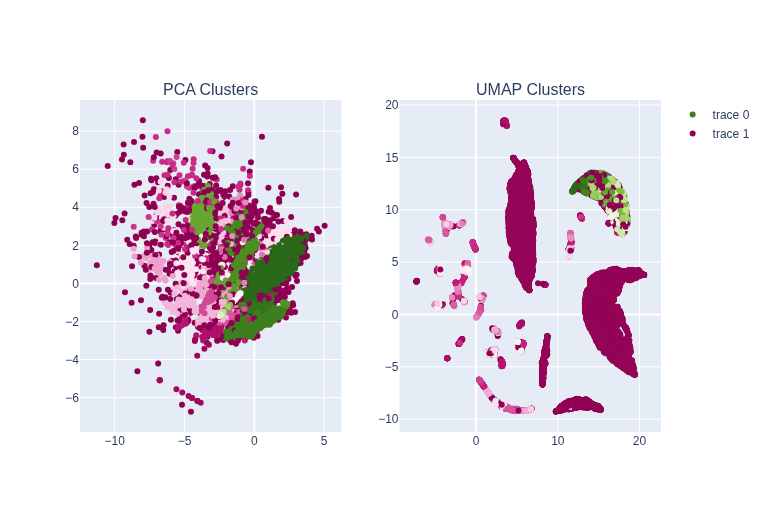

In [66]:
def pca_umap_analysis(df, cat:list, c=5, min_size=5, ground_truth="SIC2"):
    # data = df.select(cat).fill_null(0).log().to_numpy()
    n0 = df.height
    df = df.filter(pl.all_horizontal(pl.col(cat).fill_null(0) >= 0))#eliminate negative values. These probably represent production
    print(f"dropped {n0 - df.height}, {df.height} remain)")

    data = df.select(pl.col(cat).fill_null(0).cast(pl.Float64).log1p()).to_numpy()
    data = StandardScaler().fit_transform(data) #needed to scale the data
    labels = df[ground_truth].to_numpy()
    classes, y = np.unique(labels, return_inverse=True)

    print("==pca==")
    pca = PCA(n_components=c)
    pca_emb = pca.fit_transform(data)
    print("explained variance:", pca.explained_variance_ratio_.sum(), "n_components:", c)

    print("\n==umap==")
    umapper = umap.UMAP(n_components=c)
    umap_emb = umapper.fit_transform(data)
    umapper2 = umap.UMAP(n_components=2)
    umap_2d = umapper2.fit_transform(data)

    pca_clust = HDBSCAN(min_cluster_size=min_size).fit_predict(pca_emb)
    umap_clust = HDBSCAN(min_cluster_size=min_size).fit_predict(umap_emb)

    pca_non_noise = pca_clust[pca_clust != -1]
    umap_non_noise = umap_clust[umap_clust != -1]
    ari_pca = adjusted_rand_score(y[pca_clust != -1], pca_non_noise)
    ari_umap = adjusted_rand_score(y[umap_clust != -1], umap_non_noise)
    print("ARI PCA:", ari_pca, "ARI UMAP:", ari_umap)
    print(f"PCA n_clusters {len(set(pca_clust))} noise: {len(pca_clust) - len(pca_non_noise)}, UMAP n_clusters {len(set(umap_clust))} noise: {len(umap_clust) - len(umap_non_noise)}")

    subs = make_subplots(1, 2, subplot_titles=["PCA Clusters", "UMAP Clusters"])
    subs.add_trace(go.Scatter(x=pca_emb[:, 0], y=pca_emb[:, 1], mode="markers", marker=dict(color=pca_clust)), row=1, col=1)
    subs.add_trace(go.Scatter(x=umap_2d[:, 0], y=umap_2d[:, 1], mode="markers", marker=dict(color=umap_clust)), row=1, col=2)

    subs.update_layout(height=512, width=768)
    subs.show(renderer="png")

    
pca_umap_analysis(ASSESS_train, energies, c=4, min_size=5)
    

dropped 171, 18233 remain)
==pca==
explained variance: 0.6460126920616097 n_components: 4

==umap==


/home/megistus/anaconda3/envs/dali-learn/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/home/megistus/anaconda3/envs/dali-learn/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


ARI PCA: -0.0028156973069587356 ARI UMAP: 0.0035972360387396744
PCA n_clusters 84 noise: 1136, UMAP n_clusters 347 noise: 368


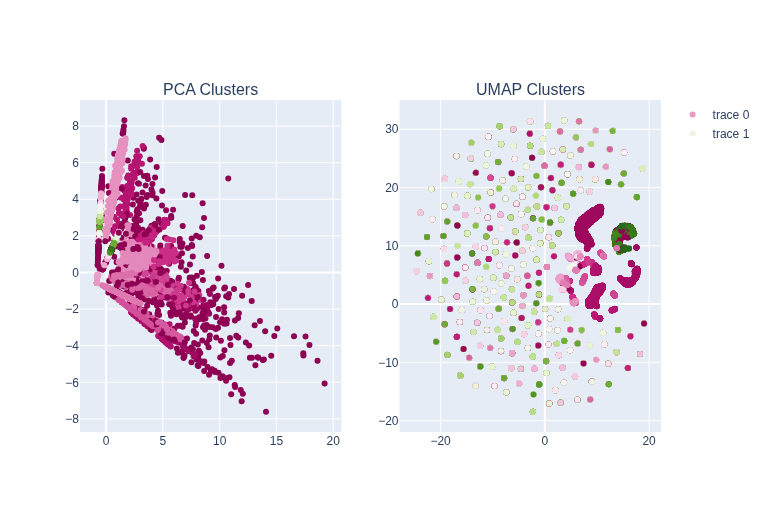

In [67]:
pca_umap_analysis(ASSESS_train, wastes, c=4, min_size=10)

Using the denser subset reduces ARI for SIC2, meaning that the sparse values are actually helping with predicting some classes. Even using the dense features, there are still a large number of noise points.

dropped 429, 17975 remain)
==pca==
explained variance: 0.9802187625002202 n_components: 3

==umap==


/home/megistus/anaconda3/envs/dali-learn/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/home/megistus/anaconda3/envs/dali-learn/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


ARI PCA: 0.0011178719732548206 ARI UMAP: 0.0005369151978612845
PCA n_clusters 408 noise: 3928, UMAP n_clusters 907 noise: 5056


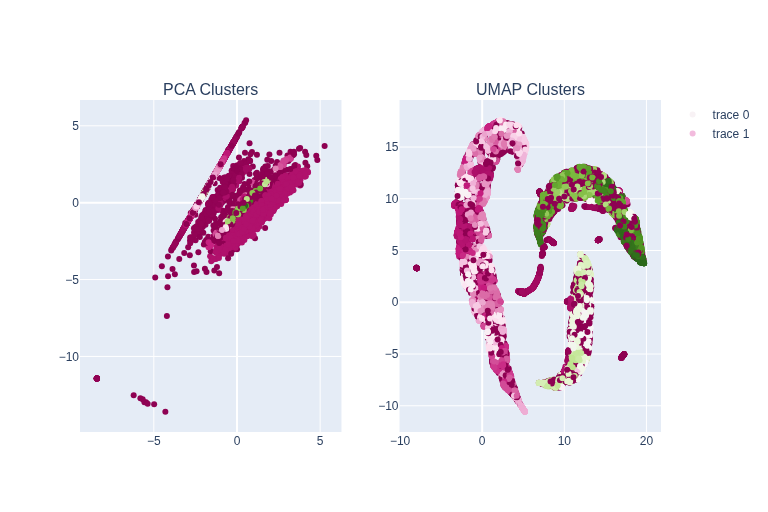

In [68]:
energy_subset = ['EC_plant_cost', 'EC_plant_usage', 'ED_plant_cost', 'ED_plant_usage', 'EF_plant_cost']
pca_umap_analysis(ASSESS_train, energy_subset, c=3, min_size=5)

Log scaing the energy data and compressing to 4 components is as good as I can do. Whether or not to keep waste is TBD.

## Recommendation Data

The recommendation sheet has a few variables that appear to be useful for classification as well. These are:

- IAC Recommendation code (ARRC2)                   (category)
- Implementation Cost (IMPCOST)                     (integer)
- Resource codes (PSOURCECODE, SSOURCECODE, etc.)   (category)
- Rebate                                            (category)
- Incremental implementation                        (binary)
- Payback (years)                                   (float)
- Capital implementation cost                       (integer)
- Other implementation cost                         (integer)

In [ ]:
cols = ['ARC2', 'IMPCOST', 'PSOURCCODE', 'SSOURCCODE', 'TSOURCCODE', 'QSOURCCODE','REBATE', 'INCREMNTAL', 'FY', 'IC_CAPITAL', 'IC_OTHER', 'PAYBACK', 'BPTOOL']


bar charts for distributions; log scaling

correlation matrix

## Finalized Data, feature reduction

feature selection

multicollinearity

# Classification models

Three models

Stacking models

Initial performance

## Hyperparameter tuning

## Evaluation metrics

## Overfitting and Underfitting

## Regularization?

## Crossvalidation

## Performance Comparison

# Conclusions